# Diabetes Prediction Dataset



# Part 1: Data Exploration



1: Load and preview the dataset

**Question:** What does the raw data look like when we load it?

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style="whitegrid")

df = pd.read_csv("C:\\Users\\hp\\Documents\\Depi\\technical\\medical\\diabetes_prediction_dataset.csv")   
df.head()

,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0


 2: Understand the dataset structure

**Question:** How big is the dataset, and what type is each column?

In [4]:
print("Shape:", df.shape)
print("Columns:", df.columns.tolist())
print()
df.info()

Shape: (100000, 9)
Columns: ['gender', 'age', 'hypertension', 'heart_disease', 'smoking_history', 'bmi', 'HbA1c_level', 'blood_glucose_level', 'diabetes']

<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 9 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   gender               100000 non-null  str    
 1   age                  100000 non-null  float64
 2   hypertension         100000 non-null  int64  
 3   heart_disease        100000 non-null  int64  
 4   smoking_history      100000 non-null  str    
 5   bmi                  100000 non-null  float64
 6   HbA1c_level          100000 non-null  float64
 7   blood_glucose_level  100000 non-null  int64  
 8   diabetes             100000 non-null  int64  
dtypes: float64(3), int64(4), str(2)
memory usage: 8.0 MB


3: Basic descriptive statistics

**Question:** What are the typical values of each numerical feature and the main categories of the categorical ones?

In [5]:
display(df.describe().T)
for col in ["gender", "smoking_history"]:
    print(f"\n--- {col} ---")
    print(df[col].value_counts())
print("\n--- Target balance ---")
print(df["diabetes"].value_counts(normalize=True).round(3))

,count,mean,std,min,25%,50%,75%,max
age,100000.0,41.885856,22.516840,0.08,24.00,43.00,60.00,80.00
hypertension,100000.0,0.074850,0.263150,0.00,0.00,0.00,0.00,1.00
heart_disease,100000.0,0.039420,0.194593,0.00,0.00,0.00,0.00,1.00
bmi,100000.0,27.320767,6.636783,10.01,23.63,27.32,29.58,95.69
HbA1c_level,100000.0,5.527507,1.070672,3.50,4.80,5.80,6.20,9.00
blood_glucose_level,100000.0,138.058060,40.708136,80.00,100.00,140.00,159.00,300.00
diabetes,100000.0,0.085000,0.278883,0.00,0.00,0.00,0.00,1.00



--- gender ---
gender
Female    58552
Male      41430
Other        18
Name: count, dtype: int64

--- smoking_history ---
smoking_history
No Info        35816
never          35095
former          9352
current         9286
not current     6447
ever            4004
Name: count, dtype: int64

--- Target balance ---
diabetes
0    0.915
1    0.085
Name: proportion, dtype: float64


# Part 2: Data Cleaning



 4: Check missing values

**Question:** Is any information missing from the data?

In [ ]:
missing = df.isna().sum()
print(missing)
print("Total missing:", missing.sum())


gender                 0
age                    0
hypertension           0
heart_disease          0
smoking_history        0
bmi                    0
HbA1c_level            0
blood_glucose_level    0
diabetes               0
dtype: int64
Total missing: 0


 5: Check duplicates

**Question:** Are there repeated rows that could bias the results?

In [ ]:
print("Fully duplicated rows:", df.duplicated().sum())
print("Duplicate % :", round(df.duplicated().mean()*100, 2), "%")
df[df.duplicated(keep=False)].sort_values(list(df.columns)).head(6)


Fully duplicated rows: 3854
Duplicate % : 3.85 %


,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
47708,Female,2.0,0,0,No Info,27.32,5.0,158,0
59468,Female,2.0,0,0,No Info,27.32,5.0,158,0
62073,Female,2.0,0,0,No Info,27.32,6.0,85,0
67439,Female,2.0,0,0,No Info,27.32,6.0,85,0
23617,Female,2.0,0,0,No Info,27.32,6.0,145,0
67234,Female,2.0,0,0,No Info,27.32,6.0,145,0


In [8]:
before = len(df)
df = df.drop_duplicates().reset_index(drop=True)
print(f"Removed {before - len(df)} duplicates -> new shape {df.shape}")

Removed 3854 duplicates -> new shape (96146, 9)


6: Inspect categorical values

**Question:** Are the category labels consistent, and do any of them hide missing information?

In [9]:
for col in ["gender", "smoking_history"]:
    print(col, "->", df[col].nunique(), "unique:", df[col].unique())
    print(df[col].value_counts(), "\n")
print(df[["hypertension", "heart_disease", "diabetes"]].apply(lambda s: sorted(s.unique())))

gender -> 3 unique: <ArrowStringArray>
['Female', 'Male', 'Other']
Length: 3, dtype: str
gender
Female    56161
Male      39967
Other        18
Name: count, dtype: int64 

smoking_history -> 6 unique: <ArrowStringArray>
['never', 'No Info', 'current', 'former', 'ever', 'not current']
Length: 6, dtype: str
smoking_history
never          34398
No Info        32887
former          9299
current         9197
not current     6367
ever            3998
Name: count, dtype: int64 

   hypertension  heart_disease  diabetes
0             0              0         0
1             1              1         1


In [10]:
df["smoking_history"] = (df["smoking_history"].str.strip().str.lower()
                         .replace({"no info": "unknown", "not current": "former", "ever": "former"}))
df["gender"] = df["gender"].str.strip().str.title()
print(df["smoking_history"].value_counts())

# بعد توحيد الـ labels ممكن يظهر تكرار جديد، فبنشيله
n = df.duplicated().sum()
df = df.drop_duplicates().reset_index(drop=True)
print(f"\nExtra duplicates after standardizing labels: {n} -> new shape {df.shape}")

smoking_history
never      34398
unknown    32887
former     19664
current     9197
Name: count, dtype: int64

Extra duplicates after standardizing labels: 178 -> new shape (95968, 9)


 7: Validate numerical ranges

**Question:** Are all numerical values medically possible?

In [11]:
num_cols = ["age", "bmi", "HbA1c_level", "blood_glucose_level"]
display(df[num_cols].agg(["min", "max"]).T)
print("Non-integer ages (like 0.08):", (df["age"] % 1 != 0).sum())
print("Age < 2:", (df["age"] < 2).sum())
print("BMI < 12 or > 60:", ((df["bmi"] < 12) | (df["bmi"] > 60)).sum())
print("Most repeated BMI value:", df["bmi"].mode()[0], "->", (df["bmi"] == df["bmi"].mode()[0]).sum(), "rows")

,min,max
age,0.08,80.00
bmi,10.01,95.69
HbA1c_level,3.50,9.00
blood_glucose_level,80.00,300.00


Non-integer ages (like 0.08): 2013
Age < 2: 2096
BMI < 12 or > 60: 198
Most repeated BMI value: 27.32 -> 21488 rows


##  8: Detect possible outliers (IQR)

**Question:** Which values are unusual, and should they be removed?

bmi                    lower=  13.67 upper=  39.59 outliers=5307 (5.5%)
HbA1c_level            lower=   2.70 upper=   8.30 outliers=1311 (1.4%)
blood_glucose_level    lower=  11.50 upper= 247.50 outliers=2030 (2.1%)


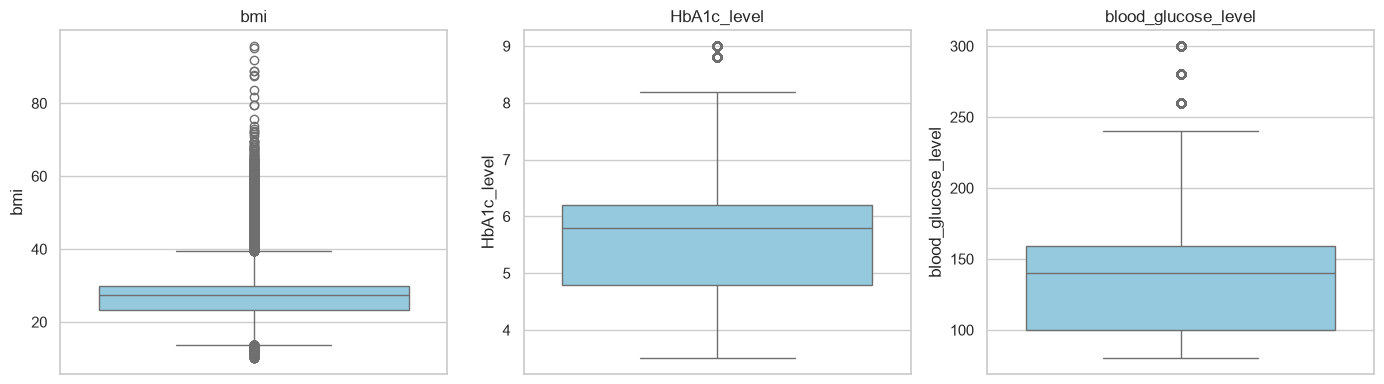

In [12]:
def iqr_outliers(s):
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    iqr = q3 - q1
    lo, hi = q1 - 1.5*iqr, q3 + 1.5*iqr
    return lo, hi, ((s < lo) | (s > hi)).sum()

for col in ["bmi", "HbA1c_level", "blood_glucose_level"]:
    lo, hi, n = iqr_outliers(df[col])
    print(f"{col:22s} lower={lo:7.2f} upper={hi:7.2f} outliers={n} ({n/len(df)*100:.1f}%)")

fig, ax = plt.subplots(1, 3, figsize=(14, 4))
for a, col in zip(ax, ["bmi", "HbA1c_level", "blood_glucose_level"]):
    sns.boxplot(y=df[col], ax=a, color="skyblue"); a.set_title(col)
plt.tight_layout(); plt.show()

**Decision:** these outliers are real clinical values (obese patients, high HbA1c/glucose), and they are exactly the diabetic cases we want to predict.  
So we **do not delete** them. For BMI only, we cap at the 99th percentile in a *separate* column to reduce the effect of extreme values.

In [13]:
df["bmi_capped"] = df["bmi"].clip(upper=df["bmi"].quantile(0.99))
df[["bmi", "bmi_capped"]].describe().T

,count,mean,std,min,25%,50%,75%,max
bmi,95968.0,27.321464,6.773989,10.01,23.39,27.32,29.87,95.69
bmi_capped,95968.0,27.267364,6.549346,10.01,23.39,27.32,29.87,48.99


# Part 3: Exploratory Data Analysis (EDA)



9: Explore one numerical variable (age)

**Question:** How is age distributed across the patients?

In [14]:
print("mean  :", round(df["age"].mean(), 2))
print("median:", df["age"].median())
print("std   :", round(df["age"].std(), 2))

df["age_group"] = pd.cut(df["age"], bins=[0, 18, 30, 45, 60, 80],
                         labels=["<18", "18-30", "31-45", "46-60", "60+"], include_lowest=True)
print(df["age_group"].value_counts().sort_index())

mean  : 41.77
median: 43.0
std   : 22.46
age_group
<18      17820
18-30    14571
31-45    19345
46-60    21698
60+      22534
Name: count, dtype: int64


 10: Categorical vs. numerical relationships

**Question:** Does the diabetes rate differ between groups (gender, smoking, age)?

In [15]:
for col in ["gender", "smoking_history", "age_group"]:
    print(f"\n--- diabetes rate by {col} ---")
    print((df.groupby(col, observed=True)["diabetes"].agg(["mean", "count"])
             .rename(columns={"mean": "diabetes_rate"}).round(3)))

print("\n--- Average values by diabetes status ---")
display(df.groupby("diabetes")[["age", "bmi", "HbA1c_level", "blood_glucose_level"]].mean().round(2))


--- diabetes rate by gender ---
        diabetes_rate  count
gender                      
Female          0.079  56042
Male            0.101  39908
Other           0.000     18

--- diabetes rate by smoking_history ---
                 diabetes_rate  count
smoking_history                      
current                  0.103   9197
former                   0.141  19486
never                    0.097  34398
unknown                  0.044  32887

--- diabetes rate by age_group ---
           diabetes_rate  count
age_group                      
<18                0.005  17820
18-30              0.014  14571
31-45              0.047  19345
46-60              0.118  21698
60+                0.209  22534

--- Average values by diabetes status ---


,age,bmi,HbA1c_level,blood_glucose_level
diabetes,,,,
0,39.91,26.87,5.40,132.81
1,60.92,32.00,6.93,194.02


 11: Explore relationships between the key features and diabetes

**Question:** Which features are most related to diabetes?

In [16]:
corr = df[["age", "hypertension", "heart_disease", "bmi", "HbA1c_level",
           "blood_glucose_level", "diabetes"]].corr()
print(corr["diabetes"].drop("diabetes").sort_values(ascending=False).round(3))

blood_glucose_level    0.425
HbA1c_level            0.407
age                    0.265
bmi                    0.215
hypertension           0.196
heart_disease          0.171
Name: diabetes, dtype: float64


# Part 4: Data Visualization




**Question:** which features move together with diabetes, and with each other?

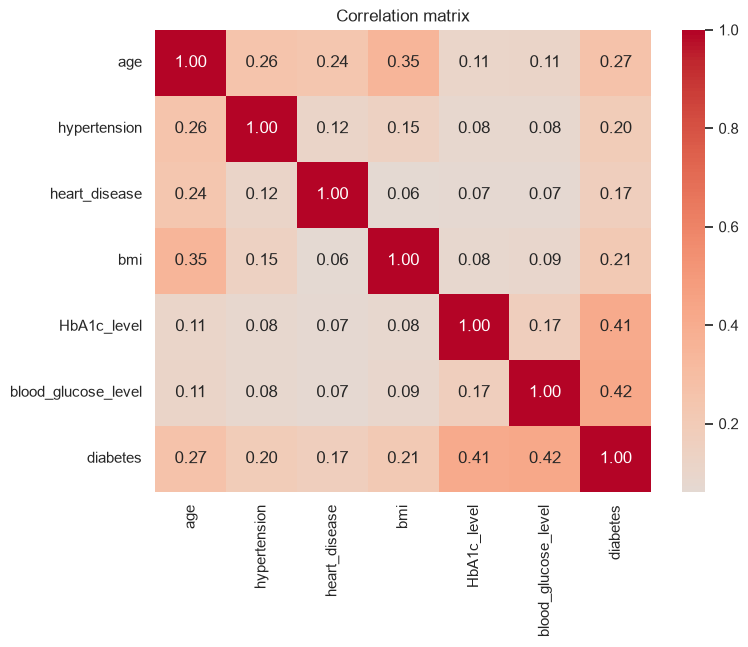

In [17]:
plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation matrix"); plt.show()

### 4.2 Do the two lab measurements separate the classes?


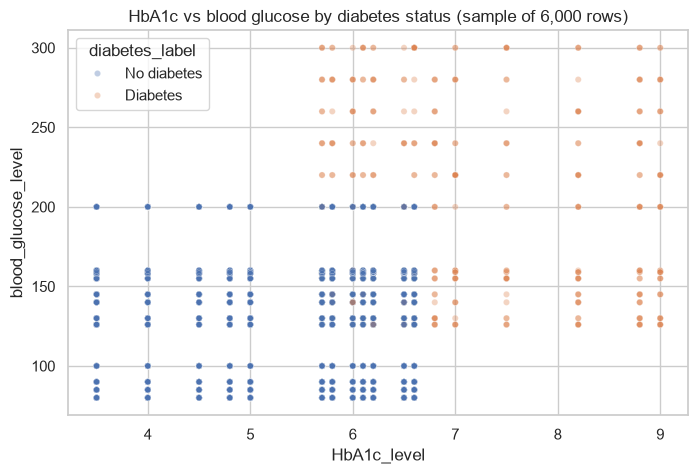

In [18]:
sample = df.sample(6000, random_state=42).assign(
    diabetes_label=lambda d: d["diabetes"].map({0: "No diabetes", 1: "Diabetes"}))
plt.figure(figsize=(8, 5))
sns.scatterplot(data=sample, x="HbA1c_level", y="blood_glucose_level", hue="diabetes_label",
                hue_order=["No diabetes", "Diabetes"], alpha=0.35, s=20)
plt.title("HbA1c vs blood glucose by diabetes status (sample of 6,000 rows)")
plt.show()

# Part 5: Feature Engineering



## TODO 12: Create a health-risk score feature

**Question:** Can several risk factors be summarized in one score?

**Rule (documented):** one point for each risk factor  
age ≥ 45, BMI ≥ 30, HbA1c ≥ 6.5, blood glucose ≥ 200, hypertension, heart disease.  
Score range = 0 to 6.

In [19]:
df["risk_score"] = ((df["age"] >= 45).astype(int)
                    + (df["bmi"] >= 30).astype(int)
                    + (df["HbA1c_level"] >= 6.5).astype(int)
                    + (df["blood_glucose_level"] >= 200).astype(int)
                    + df["hypertension"] + df["heart_disease"])
print(df["risk_score"].value_counts().sort_index())
print(df.groupby("risk_score")["diabetes"].mean().round(3))

risk_score
0    30815
1    34221
2    19797
3     7874
4     2614
5      595
6       52
Name: count, dtype: int64
risk_score
0    0.003
1    0.026
2    0.117
3    0.359
4    0.689
5    0.864
6    0.962
Name: diabetes, dtype: float64


 13: Create a BMI category

**Question:** Can BMI be grouped into meaningful categories?

In [20]:
df["bmi_category"] = pd.cut(df["bmi"], bins=[0, 18.5, 25, 30, 100],
                            labels=["Underweight", "Normal", "Overweight", "Obese"], right=False)
print(df["bmi_category"].value_counts())
print(df.groupby("bmi_category", observed=True)["diabetes"].mean().round(3))

bmi_category
Overweight     41739
Obese          23530
Normal         22208
Underweight     8491
Name: count, dtype: int64
bmi_category
Underweight    0.008
Normal         0.039
Overweight     0.080
Obese          0.180
Name: diabetes, dtype: float64


14: Create an interaction feature

**Question:** Do combinations of features carry extra information?

In [21]:
df["hba1c_x_glucose"] = df["HbA1c_level"] * df["blood_glucose_level"]
df["age_x_bmi"] = df["age"] * df["bmi"]
print(df[["hba1c_x_glucose", "age_x_bmi", "diabetes"]].corr()["diabetes"].round(3))

hba1c_x_glucose    0.570
age_x_bmi          0.322
diabetes           1.000
Name: diabetes, dtype: float64


# Part 6:EDA




## 6.1 Setup for the structured EDA

In [22]:
TARGET = "diabetes"
NUMERIC_FEATURES = ["age", "bmi", "HbA1c_level", "blood_glucose_level"]
CATEGORICAL_FEATURES = ["gender", "hypertension", "heart_disease", "smoking_history",
                        "age_group", "bmi_category", "risk_score"]
TARGET_LABELS = {0: "No diabetes", 1: "Diabetes"}
MIN_GROUP_SIZE = 30

# Analysis copy: the cleaned df stays unchanged for the final review.
eda = df.copy()
print("Missing values:", eda.isna().sum().sum(), "| Duplicates:", eda.duplicated().sum())

CLASS_COL = "__target_label__"
eda[CLASS_COL] = eda[TARGET].map(TARGET_LABELS)
class_order = [TARGET_LABELS[0], TARGET_LABELS[1]]
class_colors = dict(zip(class_order, sns.color_palette("colorblind", 2)))

for col in CATEGORICAL_FEATURES:
    eda[col] = eda[col].astype("string").fillna("<Missing>")

category_orders = {c: eda[c].value_counts().index.tolist() for c in CATEGORICAL_FEATURES}
# natural order for the ordered features
category_orders["age_group"] = ["<18", "18-30", "31-45", "46-60", "60+"]
category_orders["bmi_category"] = ["Underweight", "Normal", "Overweight", "Obese"]
category_orders["risk_score"] = [str(i) for i in range(7)]
print(f"Analysis population: {len(eda):,} rows")

Missing values: 0 | Duplicates: 0
Analysis population: 95,968 rows


In [23]:
def subplot_grid(n, ncols=2, width=6, height=4):
    """Return a figure and n usable axes; hide any unused panels."""
    ncols = min(ncols, max(1, n))
    nrows = int(np.ceil(max(1, n) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(width * ncols, height * nrows),
                             squeeze=False, constrained_layout=True)
    flat = axes.ravel()
    for ax in flat[n:]:
        ax.set_visible(False)
    return fig, flat[:n]

def label_bars(ax, fmt="%.1f"):
    for container in ax.containers:
        ax.bar_label(container, fmt=fmt, fontsize=8, padding=3)
    ax.margins(y=0.18)

## 6.2 Understand the target first
**Question:** are the classes equally represented?  
Countplot = exact counts. Pie chart = the same data as percentages.

,rows,percent
__target_label__,,
No diabetes,87487,91.162679
Diabetes,8481,8.837321


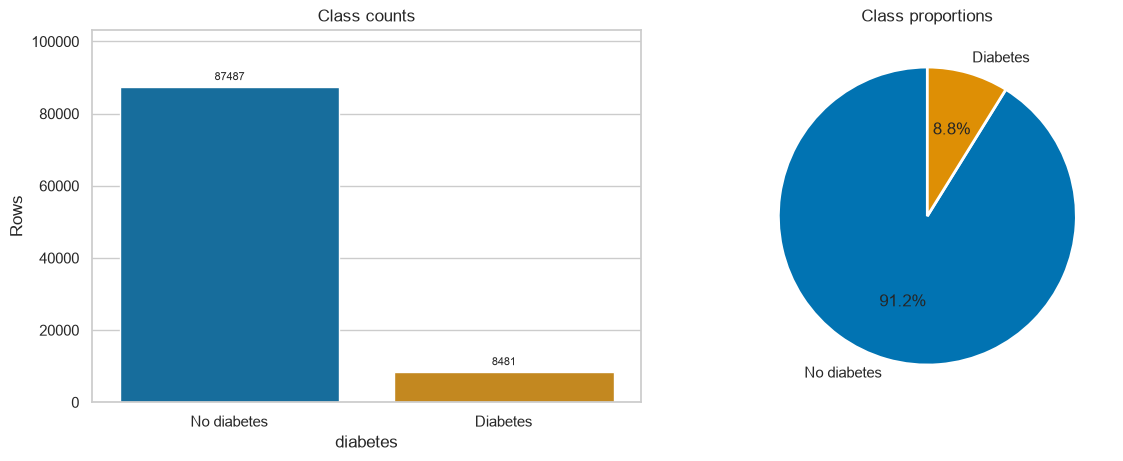

Majority-class baseline: 91.16%


In [24]:
target_counts = eda[CLASS_COL].value_counts().reindex(class_order)
display(pd.DataFrame({"rows": target_counts, "percent": target_counts / len(eda) * 100}))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), constrained_layout=True)
sns.countplot(data=eda, x=CLASS_COL, order=class_order, hue=CLASS_COL,
              palette=class_colors, legend=False, ax=axes[0])
axes[0].set(title="Class counts", xlabel=TARGET, ylabel="Rows")
label_bars(axes[0], "%.0f")
axes[1].pie(target_counts, labels=class_order, autopct="%1.1f%%", startangle=90,
            colors=[class_colors[c] for c in class_order],
            wedgeprops={"edgecolor": "white", "linewidth": 2})
axes[1].set_title("Class proportions")
plt.show()
print(f"Majority-class baseline: {target_counts.max() / len(eda):.2%}")

## 6.3 One feature at a time: numerical distributions
**Question:** where are values concentrated, and are there skewness, gaps or spikes? One histogram per feature.

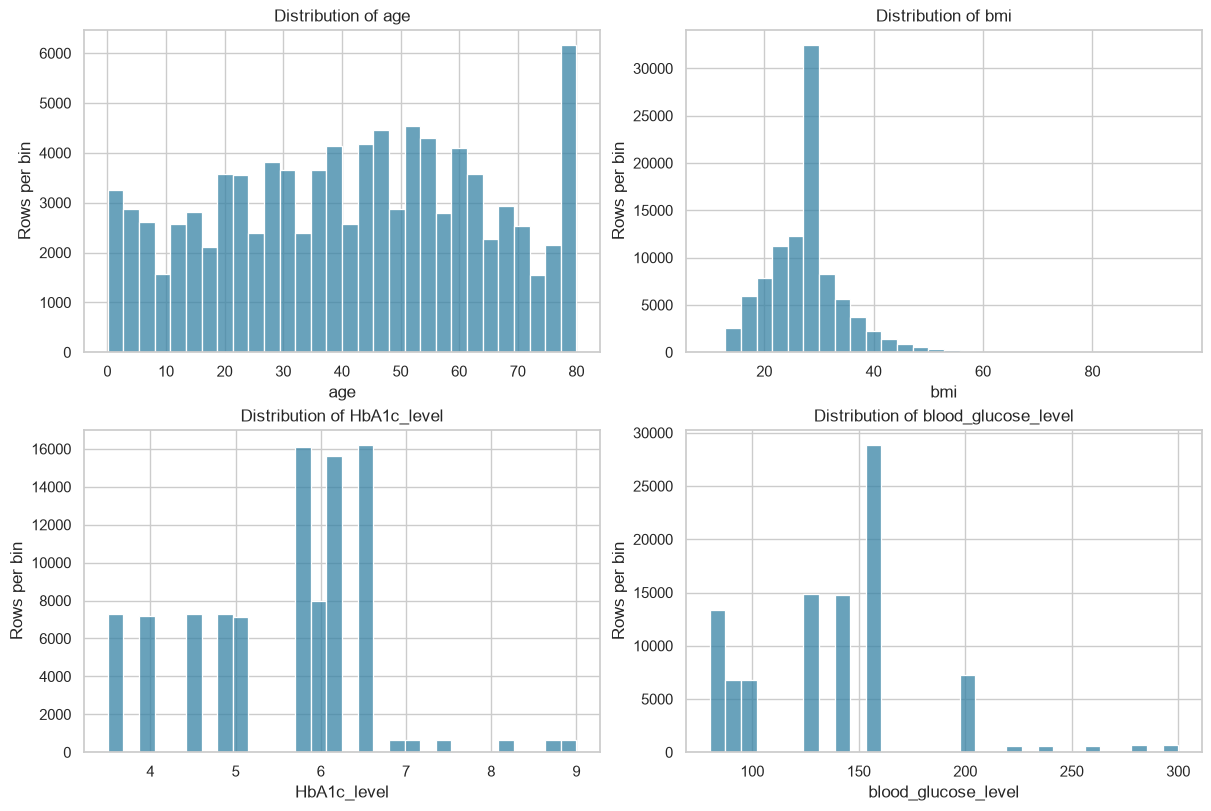

In [25]:
fig, axes = subplot_grid(len(NUMERIC_FEATURES))
for ax, col in zip(axes, NUMERIC_FEATURES):
    sns.histplot(data=eda, x=col, bins=30, color="#3783a5", ax=ax)
    ax.set(title=f"Distribution of {col}", ylabel="Rows per bin")
plt.show()

**Bin choice changes the view:** the same BMI data with 10, 30 and 60 bins.

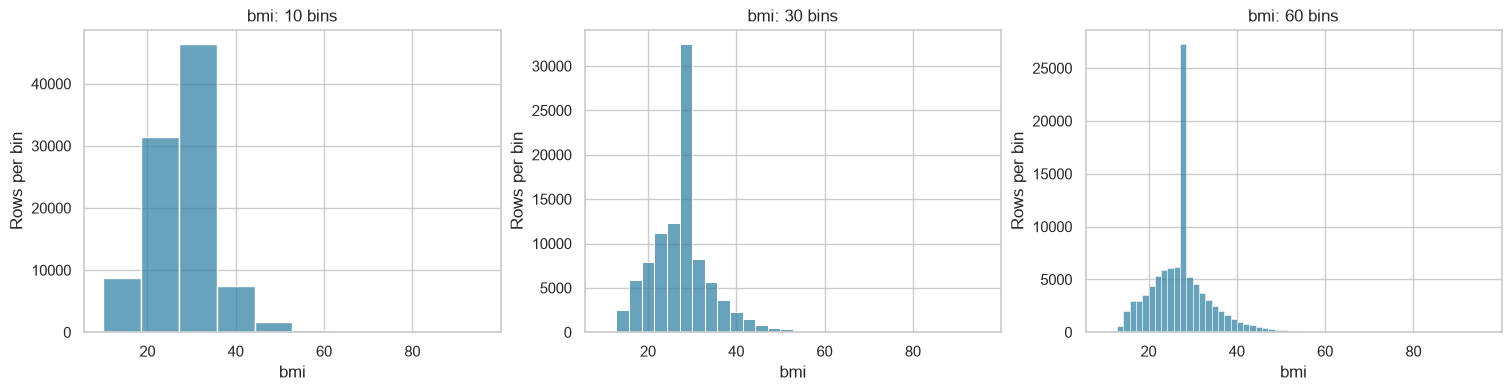

In [26]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8), sharex=True, constrained_layout=True)
for ax, bins in zip(axes, [10, 30, 60]):
    sns.histplot(data=eda, x="bmi", bins=bins, color="#3783a5", ax=ax)
    ax.set(title=f"bmi: {bins} bins", ylabel="Rows per bin")
plt.show()

## 6.4 One feature at a time: categorical frequencies
**Question:** which categories are common or rare? Horizontal countplots keep labels readable.

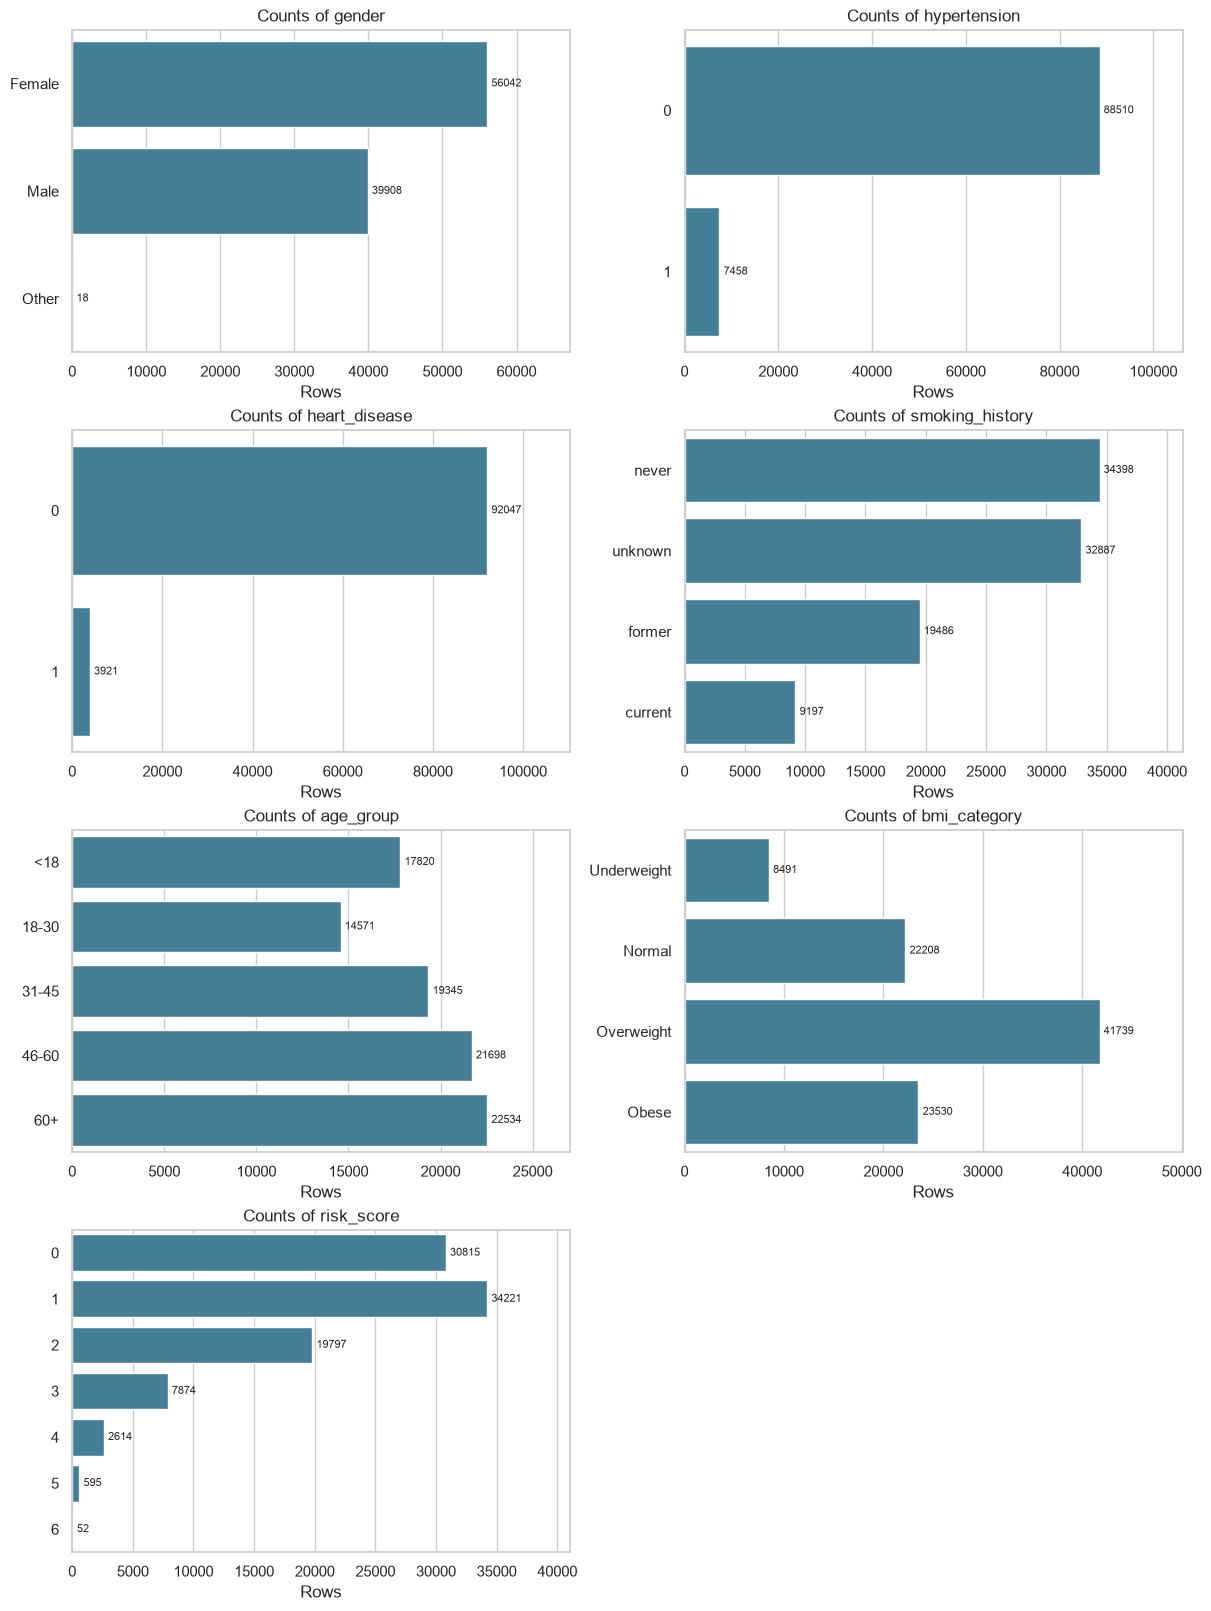

In [27]:
fig, axes = subplot_grid(len(CATEGORICAL_FEATURES))
for ax, col in zip(axes, CATEGORICAL_FEATURES):
    sns.countplot(data=eda, y=col, order=category_orders[col], color="#3783a5", ax=ax)
    ax.set(title=f"Counts of {col}", xlabel="Rows", ylabel="")
    for container in ax.containers:
        ax.bar_label(container, fmt="%.0f", fontsize=8, padding=3)
    ax.margins(x=0.2)
plt.show()

## 6.5 Boxplots and possible outliers
**Question:** which measurements have unusual values? Points beyond **[Q1 − 1.5·IQR, Q3 + 1.5·IQR]** are *candidates* for investigation, not errors.

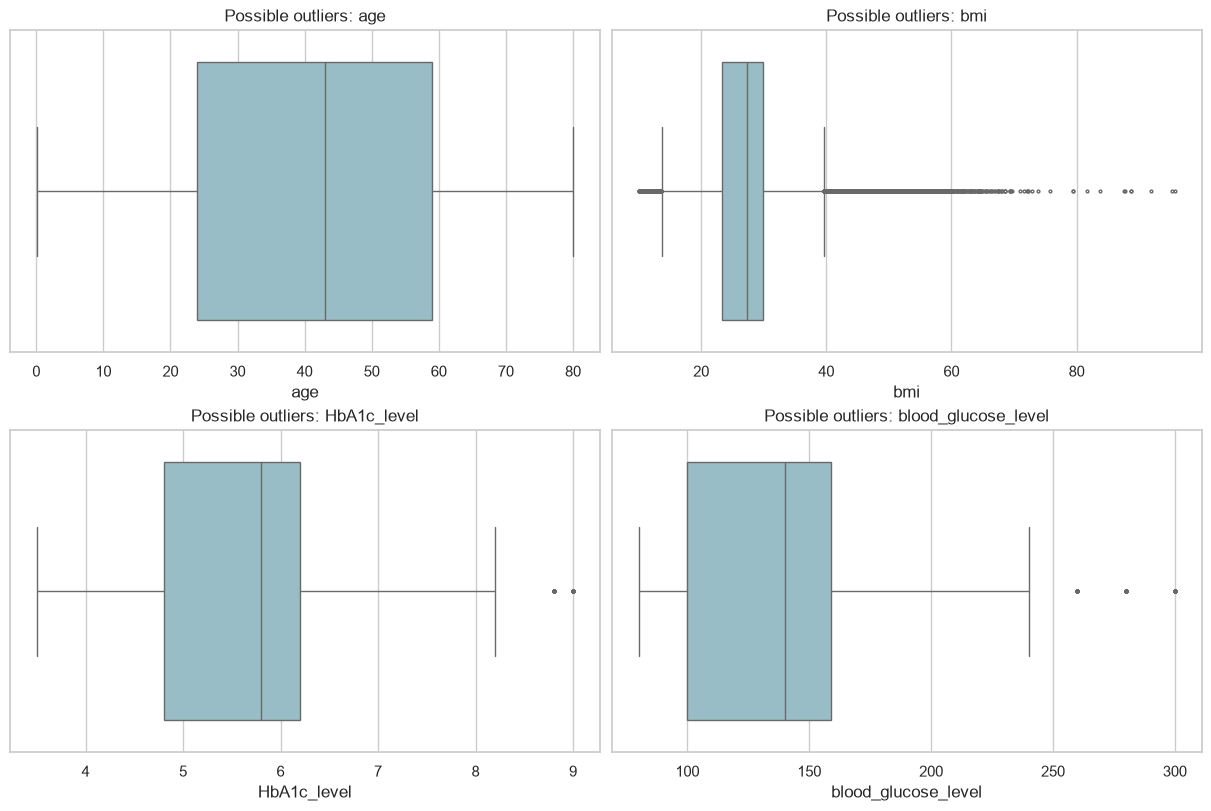

,feature,Q1,Q3,IQR,lower_fence,upper_fence,flagged_n,observed_n,flagged_pct
0,age,24.00,59.00,35.00,-28.50,111.50,0,95968,0.000000
1,bmi,23.39,29.87,6.48,13.67,39.59,5307,95968,5.529968
2,HbA1c_level,4.80,6.20,1.40,2.70,8.30,1311,95968,1.366080
3,blood_glucose_level,100.00,159.00,59.00,11.50,247.50,2030,95968,2.115288


Flagged rows have been retained.


In [28]:
outlier_rows = []
fig, axes = subplot_grid(len(NUMERIC_FEATURES))
for ax, col in zip(axes, NUMERIC_FEATURES):
    sns.boxplot(data=eda, x=col, color="#91c2ce", fliersize=2, ax=ax)
    ax.set_title(f"Possible outliers: {col}")
    x = eda[col].dropna()
    q1, q3 = x.quantile([0.25, 0.75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    flagged = (x < lower) | (x > upper)
    outlier_rows.append({"feature": col, "Q1": q1, "Q3": q3, "IQR": iqr,
                         "lower_fence": lower, "upper_fence": upper,
                         "flagged_n": int(flagged.sum()), "observed_n": len(x),
                         "flagged_pct": flagged.mean() * 100})
plt.show()
display(pd.DataFrame(outlier_rows))
print("Flagged rows have been retained.")

## 6.6 Numerical feature vs target: compare whole distributions
**Question:** does each class occupy a different part of the range?  
`stat="density"` and `common_norm=False` give each class an area of 1, so shapes can be compared despite the imbalance.

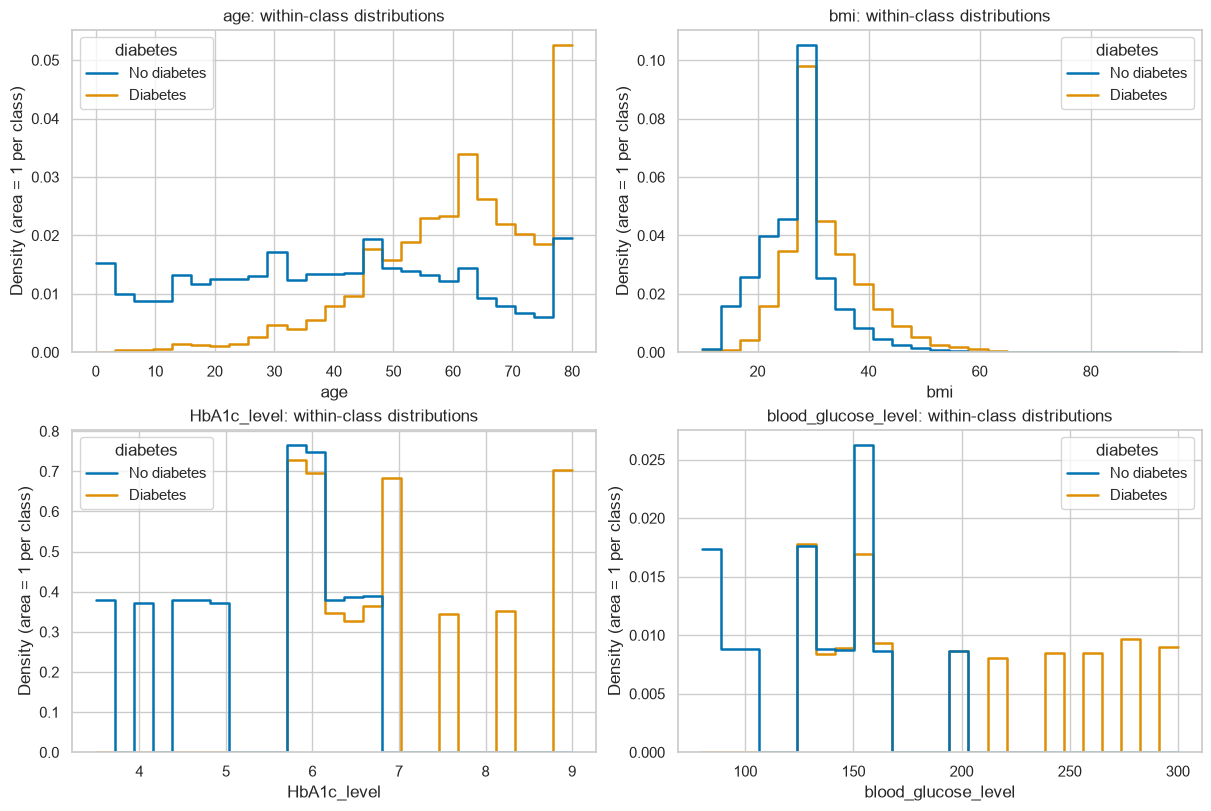

In [29]:
fig, axes = subplot_grid(len(NUMERIC_FEATURES))
for ax, col in zip(axes, NUMERIC_FEATURES):
    sns.histplot(data=eda, x=col, hue=CLASS_COL, hue_order=class_order,
                 palette=class_colors, bins=25, stat="density", common_norm=False,
                 common_bins=True, element="step", fill=False, linewidth=1.8, ax=ax)
    ax.set(title=f"{col}: within-class distributions", ylabel="Density (area = 1 per class)")
    if ax.get_legend() is not None:
        ax.get_legend().set_title(TARGET)
plt.show()

**Grouped boxplots:** medians, spread and unusual cases per class.

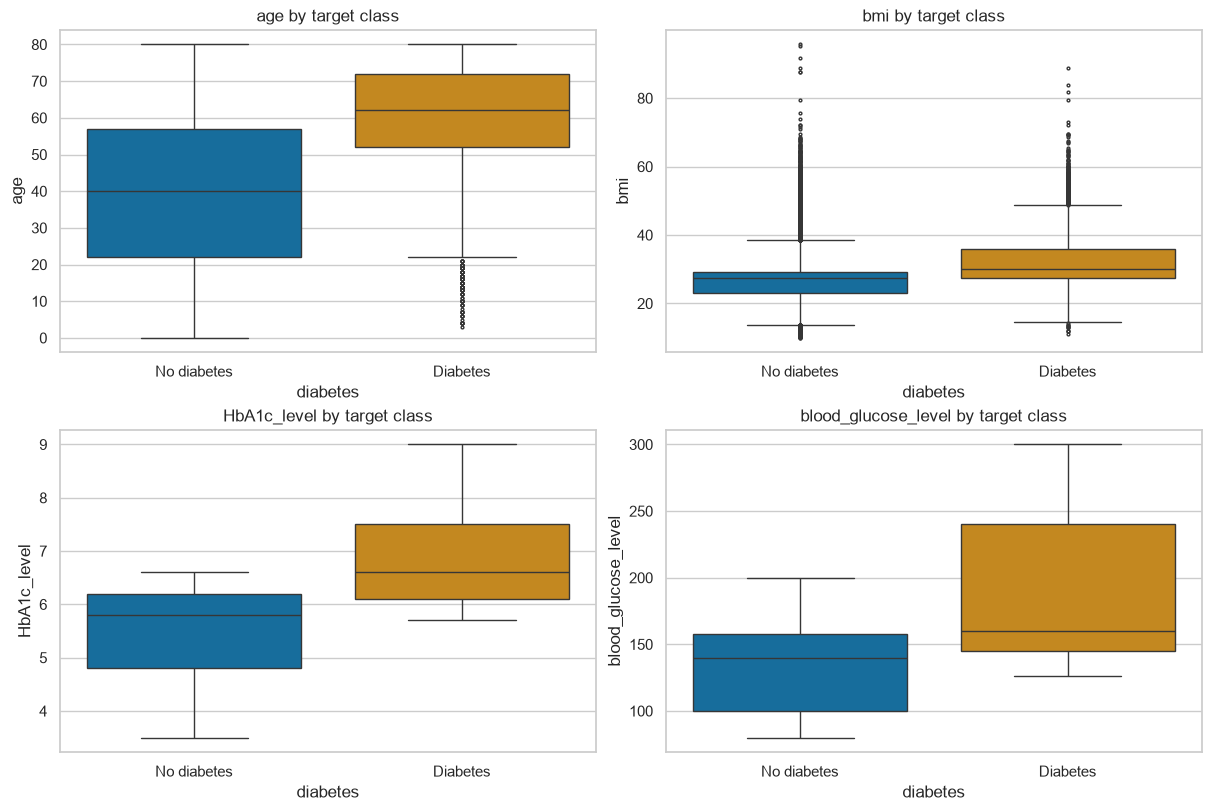

In [30]:
fig, axes = subplot_grid(len(NUMERIC_FEATURES))
for ax, col in zip(axes, NUMERIC_FEATURES):
    sns.boxplot(data=eda, x=CLASS_COL, y=col, order=class_order, hue=CLASS_COL,
                palette=class_colors, legend=False, fliersize=2, ax=ax)
    ax.set(title=f"{col} by target class", xlabel=TARGET)
plt.show()

## 6.7 Mean, minimum and maximum of each numerical feature by class
**Question:** how do the average and the observed extremes differ between classes?  
`sns.barplot(estimator=...)` changes the statistic. Compare class heights **within** each panel.

In [31]:
display(eda.groupby(CLASS_COL)[NUMERIC_FEATURES].agg(["mean", "median", "min", "max"]).T.round(2))

__target_label__            Diabetes  No diabetes
age                 mean       60.92        39.91
                    median     62.00        40.00
                    min         3.00         0.08
                    max        80.00        80.00
bmi                 mean       32.00        26.87
                    median     29.99        27.32
                    min        10.98        10.01
                    max        88.72        95.69
HbA1c_level         mean        6.93         5.40
                    median      6.60         5.80
                    min         5.70         3.50
                    max         9.00         6.60
blood_glucose_level mean      194.02       132.81
                    median    160.00       140.00
                    min       126.00        80.00
                    max       300.00       200.00

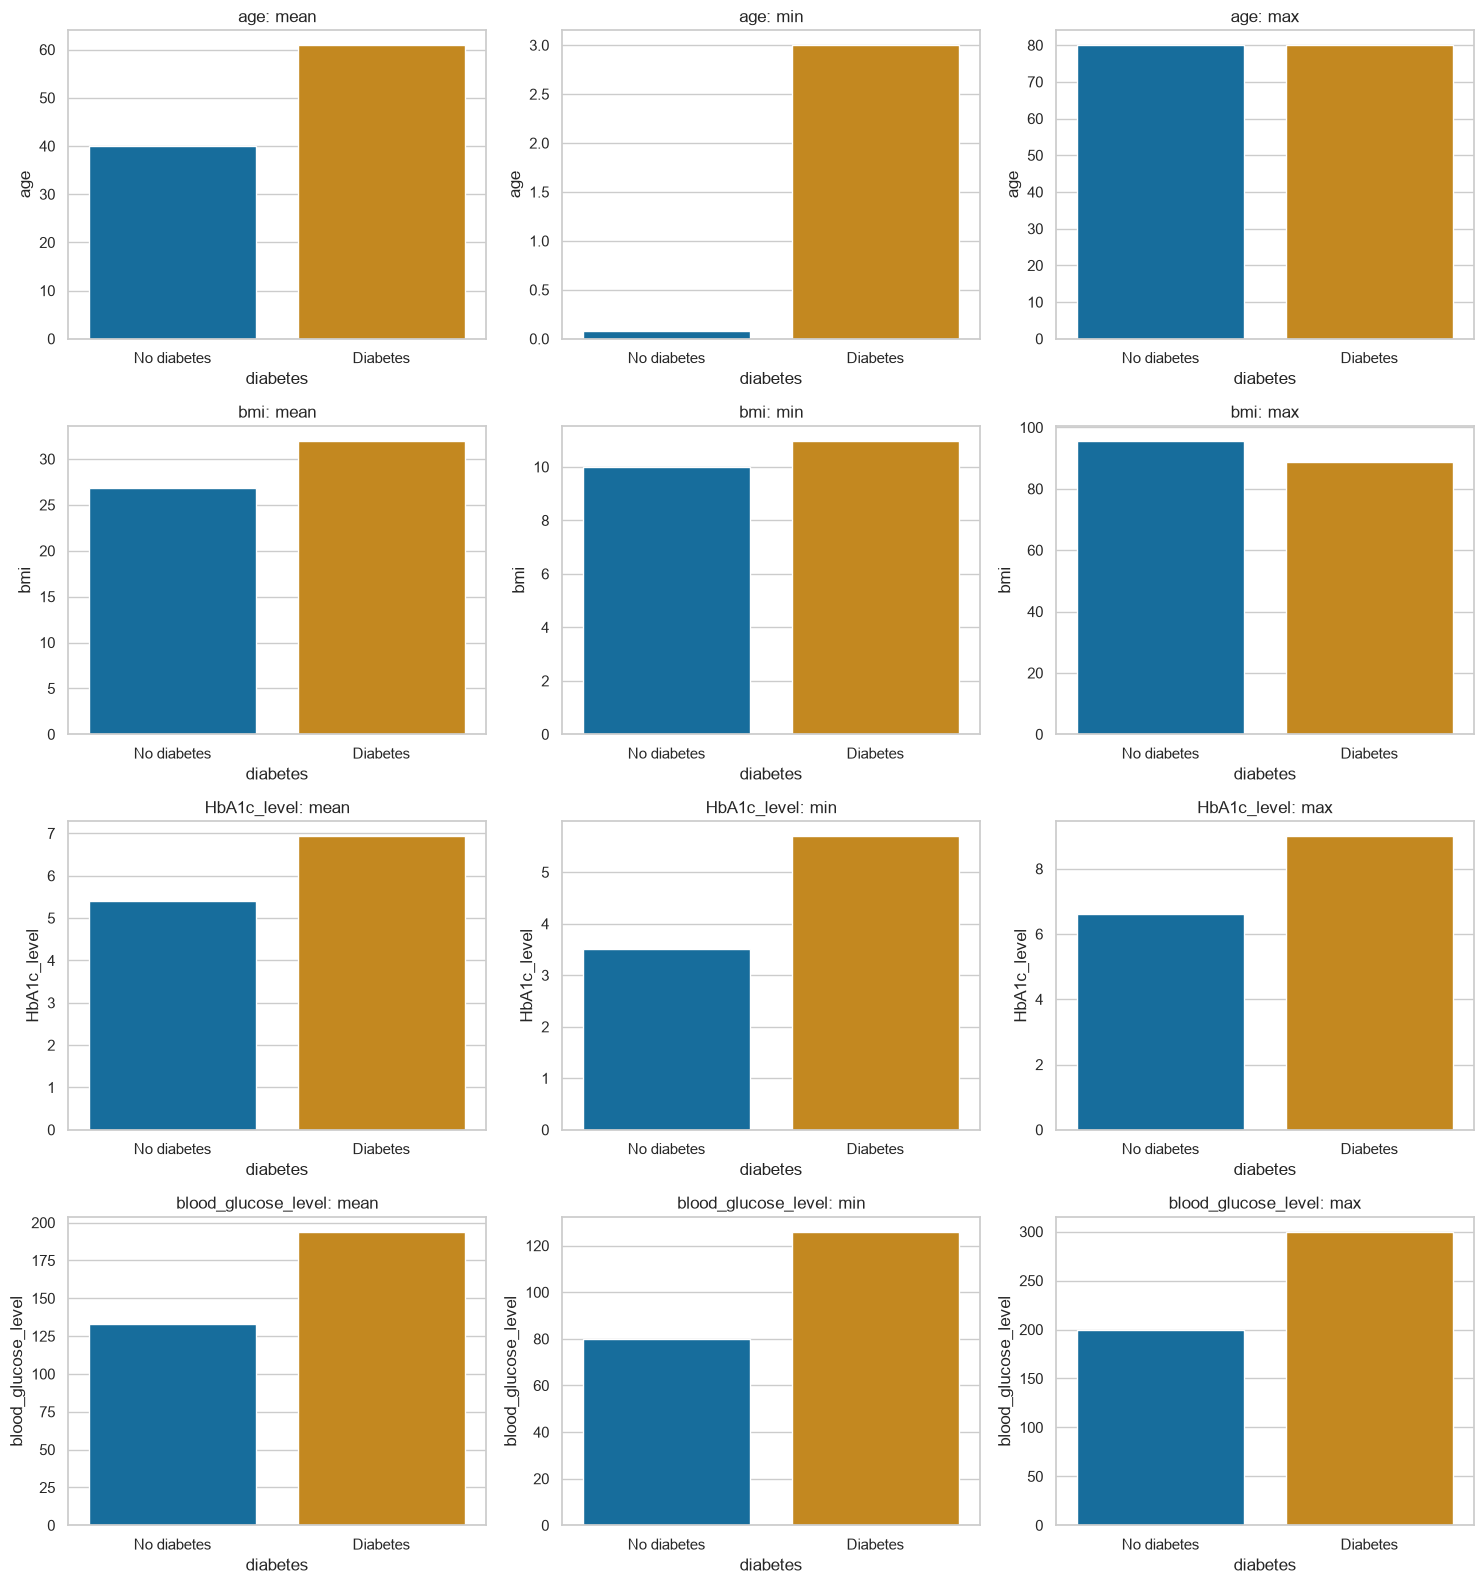

In [32]:
statistics = ["mean", "min", "max"]
plt.figure(figsize=(15, 4 * len(NUMERIC_FEATURES)))
plot_number = 1
for column in NUMERIC_FEATURES:
    for statistic in statistics:
        plt.subplot(len(NUMERIC_FEATURES), 3, plot_number)
        sns.barplot(data=eda, x=CLASS_COL, y=column, order=class_order, hue=CLASS_COL,
                    palette=class_colors, legend=False, estimator=statistic, errorbar=None)
        plt.title(f"{column}: {statistic}")
        plt.xlabel(TARGET)
        plot_number += 1
plt.tight_layout()
plt.show()

## 6.8 Categorical feature vs target: counts and rates answer different questions
### 6.8A Grouped counts
**Question:** how many rows of each class occur in each category? A big category can have more positives just because it has more rows.

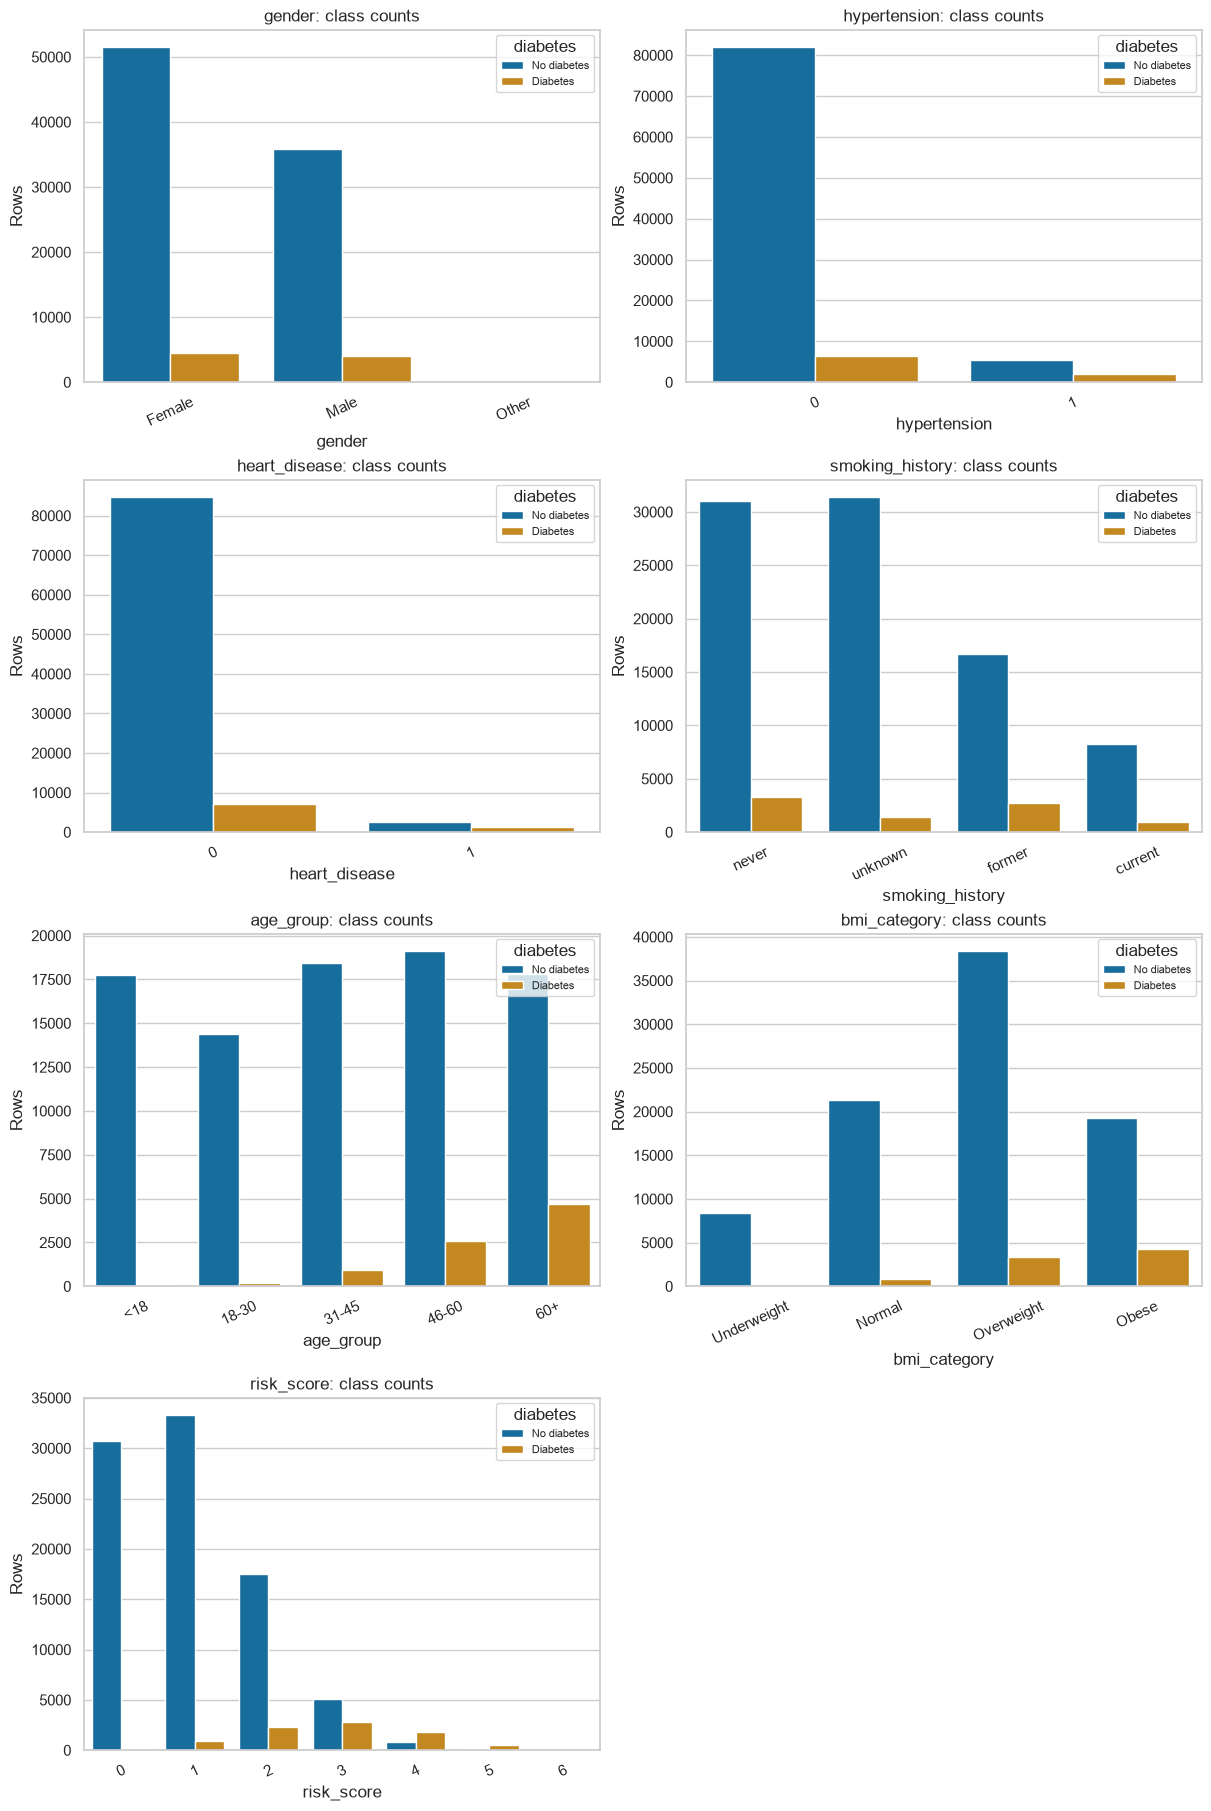

In [33]:
fig, axes = subplot_grid(len(CATEGORICAL_FEATURES), height=4.5)
for ax, col in zip(axes, CATEGORICAL_FEATURES):
    sns.countplot(data=eda, x=col, hue=CLASS_COL, order=category_orders[col],
                  hue_order=class_order, palette=class_colors, ax=ax)
    ax.set(title=f"{col}: class counts", ylabel="Rows")
    ax.tick_params(axis="x", rotation=25)
    ax.legend(title=TARGET, fontsize=8)
plt.show()

### 6.8B Class percentages within each category
**Question:** among the rows in a category, what percentage belongs to each class?  
`pd.crosstab(..., normalize="index")` divides by the category size. The group size `n` is shown, because a rate from a few rows is unstable.


gender: percentages within each category


__target_label__,No diabetes,Diabetes,n,small_group
gender,,,,
Female,92.06,7.94,56042,False
Male,89.89,10.11,39908,False
Other,100.00,0.00,18,True



hypertension: percentages within each category


__target_label__,No diabetes,Diabetes,n,small_group
hypertension,,,,
0,92.77,7.23,88510,False
1,72.03,27.97,7458,False



heart_disease: percentages within each category


...

__target_label__,No diabetes,Diabetes,n,small_group
age_group,,,,
<18,99.48,0.52,17820,False
18-30,98.57,1.43,14571,False
31-45,95.29,4.71,19345,False
46-60,88.19,11.81,21698,False
60+,79.12,20.88,22534,False



bmi_category: percentages within each category


__target_label__,No diabetes,Diabetes,n,small_group
bmi_category,,,,
Underweight,99.25,0.75,8491,False
Normal,96.11,3.89,22208,False
Overweight,92.04,7.96,41739,False
Obese,82.01,17.99,23530,False



risk_score: percentages within each category


__target_label__,No diabetes,Diabetes,n,small_group
risk_score,,,,
0,99.67,0.33,30815,False
1,97.43,2.57,34221,False
2,88.34,11.66,19797,False
3,64.10,35.90,7874,False
4,31.14,68.86,2614,False
5,13.61,86.39,595,False
6,3.85,96.15,52,False


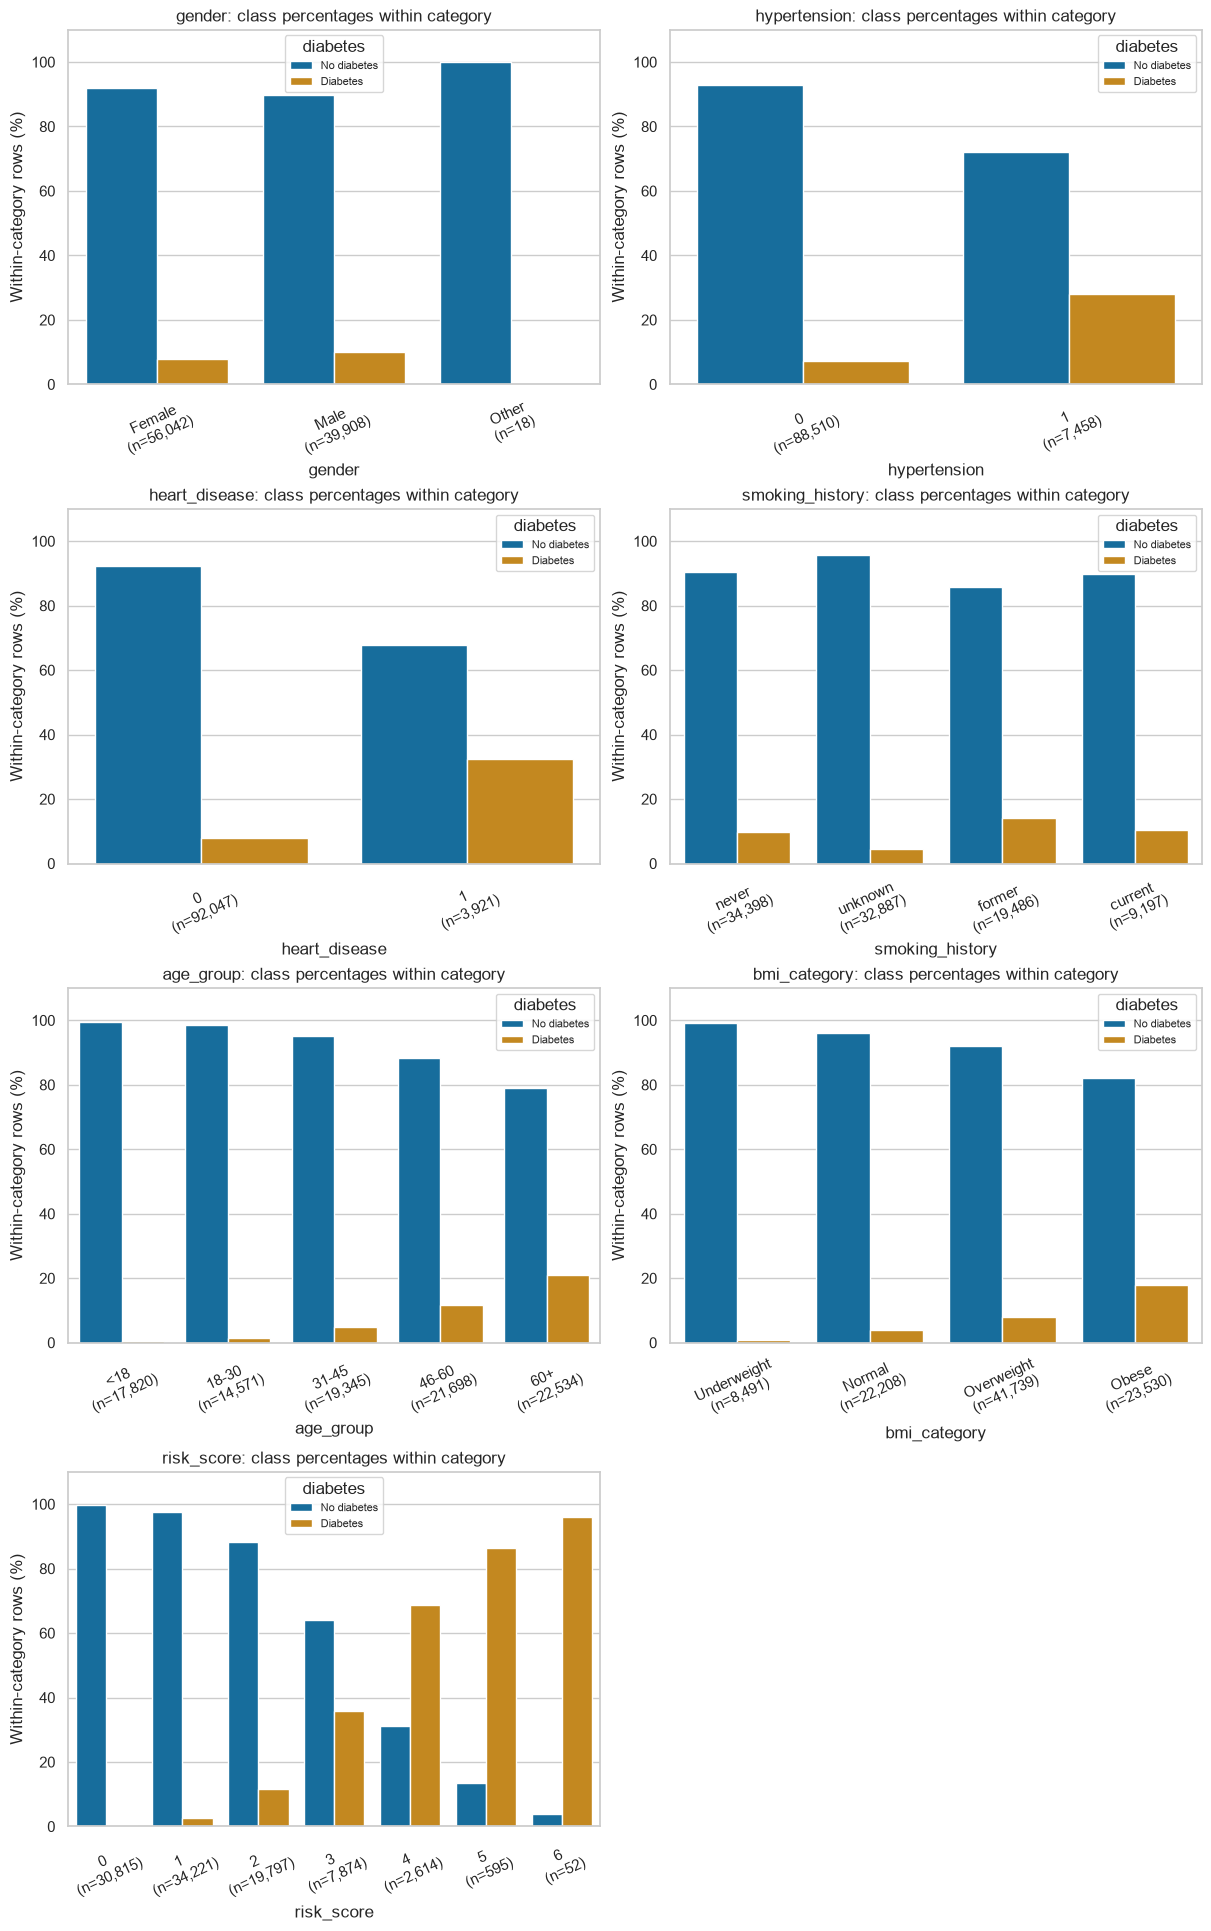

In [34]:
category_tables = {}
fig, axes = subplot_grid(len(CATEGORICAL_FEATURES), height=4.8)
for ax, col in zip(axes, CATEGORICAL_FEATURES):
    counts = pd.crosstab(eda[col], eda[CLASS_COL]).reindex(
        index=category_orders[col], columns=class_order, fill_value=0)
    support = counts.sum(axis=1)
    percentages = counts.div(support, axis=0) * 100
    category_tables[col] = (counts, percentages)
    print(f"\n{col}: percentages within each category")
    display(percentages.round(2).assign(n=support, small_group=support < MIN_GROUP_SIZE))

    plot_rates = percentages.rename_axis(index="category", columns="target_class").reset_index()
    plot_rates = plot_rates.melt(id_vars="category", var_name="target_class", value_name="percent")
    sns.barplot(data=plot_rates, x="category", y="percent", hue="target_class",
                order=category_orders[col], hue_order=class_order,
                palette=class_colors, errorbar=None, ax=ax)
    ax.set(title=f"{col}: class percentages within category", xlabel=col,
           ylabel="Within-category rows (%)", ylim=(0, 110))
    ax.set_xticks(range(len(support)))
    ax.set_xticklabels([f"{cat}\n(n={support[cat]:,})" for cat in support.index], rotation=25)
    ax.legend(title=TARGET, fontsize=8)
plt.show()

## 6.9 Lab values: how does the diabetes rate change along the recorded values?
**Question:** HbA1c and glucose are recorded at only 18 distinct values each. Because these values are ordered, a lineplot of the diabetes rate at each value is meaningful here.


HbA1c_level


HbA1c_level,3.5,4.0,4.5,4.8,5.0,5.7,5.8,6.0,6.1,6.2,6.5,6.6,6.8,7.0,7.5,8.2,8.8,9.0
rate,0.0,0.0,0.0,0.0,0.0,8.65,8.25,8.1,8.46,8.14,7.57,8.37,100.0,100.0,100.0,100.0,100.0,100.0
n,7303.0,7179.0,7282.0,7278.0,7143.0,8111.00,7976.00,7976.0,7698.00,7939.00,8044.00,8152.00,642.0,633.0,642.0,659.0,660.0,651.0



blood_glucose_level


blood_glucose_level,80,85,90,100,126,130,140,145,155,158,159,160,200,220,240,260,280,300
rate,0.0,0.0,0.0,0.0,8.59,9.26,8.44,9.0,8.22,0.0,8.93,9.4,8.89,100.0,100.0,100.0,100.0,100.0
n,6774.0,6619.0,6810.0,6760.0,7408.00,7452.00,7409.00,7359.0,7275.00,6721.0,7462.00,7380.0,7276.00,600.0,633.0,634.0,723.0,673.0


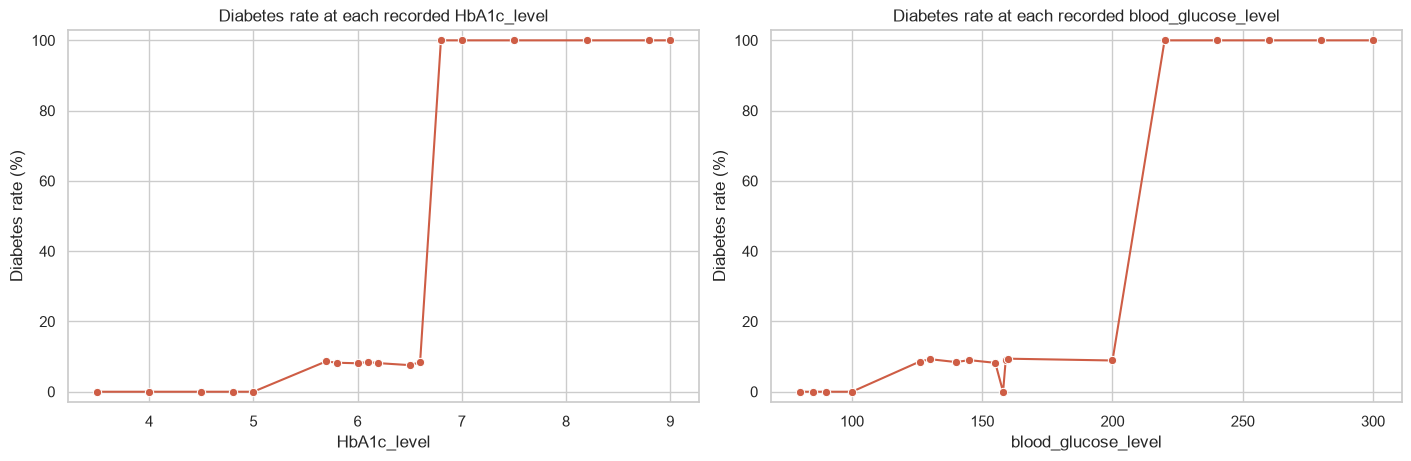

In [35]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), constrained_layout=True)
for ax, col in zip(axes, ["HbA1c_level", "blood_glucose_level"]):
    rate = eda.groupby(col)[TARGET].agg(rate="mean", n="size").reset_index()
    rate["rate"] = rate["rate"] * 100
    sns.lineplot(data=rate, x=col, y="rate", marker="o", color="#ce5d45", ax=ax)
    ax.set(title=f"Diabetes rate at each recorded {col}", ylabel="Diabetes rate (%)", ylim=(-3, 103))
    print(f"\n{col}")
    display(rate.set_index(col).T.round(2))
plt.show()

## 6.10 Does age explain the hypertension and heart-disease effect?
**Question:** patients with hypertension or heart disease are older. Does their higher diabetes rate survive when we compare people of the **same age group**? (Groups with fewer than 30 rows are left out.)

rate              n        
hypertension     0     1        0       1
age_group                                
<18            0.5   0.0  17810.0    10.0
18-30          1.3  12.1  14447.0   124.0
31-45          4.1  18.5  18501.0   844.0
46-60         10.1  26.1  19334.0  2364.0
60+           18.5  31.5  18418.0  4116.0

rate              n        
heart_disease     0     1        0       1
age_group                                 
<18             0.5  20.0  17815.0     5.0
18-30           1.4   0.0  14561.0    10.0
31-45           4.6  24.3  19205.0   140.0
46-60          11.1  29.8  20842.0   856.0
60+            19.0  33.6  19624.0  2910.0

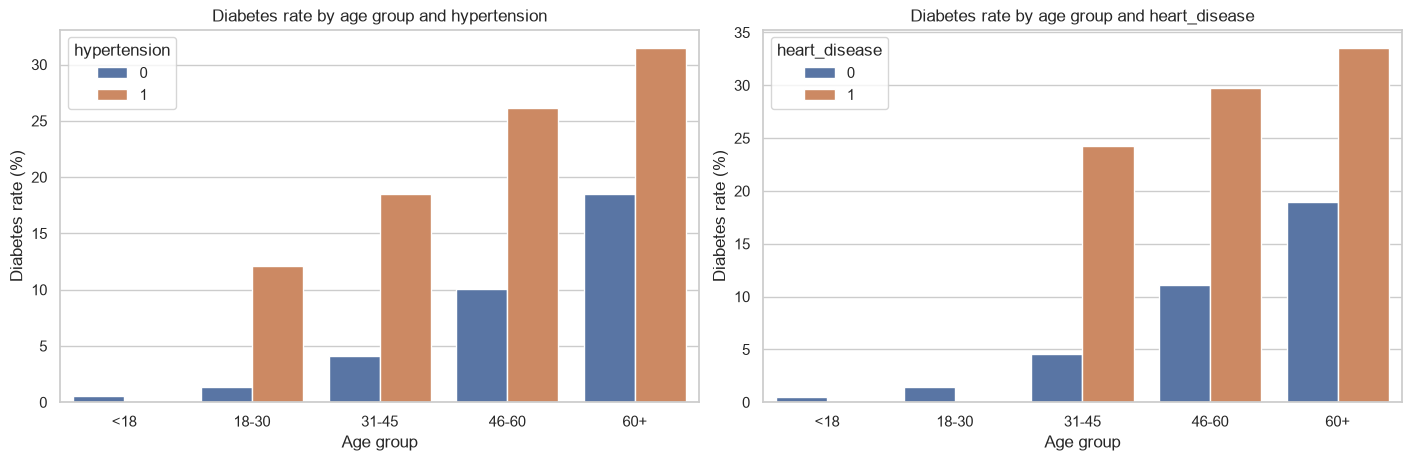

In [36]:
age_order = category_orders["age_group"]
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), constrained_layout=True)
for ax, col in zip(axes, ["hypertension", "heart_disease"]):
    adj = (eda.groupby(["age_group", col])[TARGET].agg(rate="mean", n="size").reset_index())
    adj["rate"] = adj["rate"] * 100
    display(adj.pivot(index="age_group", columns=col, values=["rate", "n"]).reindex(age_order).round(1))
    adj = adj[adj["n"] >= MIN_GROUP_SIZE]
    sns.barplot(data=adj, x="age_group", y="rate", hue=col, order=age_order,
                hue_order=["0", "1"], errorbar=None, ax=ax)
    ax.set(title=f"Diabetes rate by age group and {col}", ylabel="Diabetes rate (%)", xlabel="Age group")
plt.show()

## 6.11 Age group and BMI category together
**Question:** is the diabetes rate highest where older age and obesity combine? A rate heatmap is read together with a heatmap of how many rows support each cell.

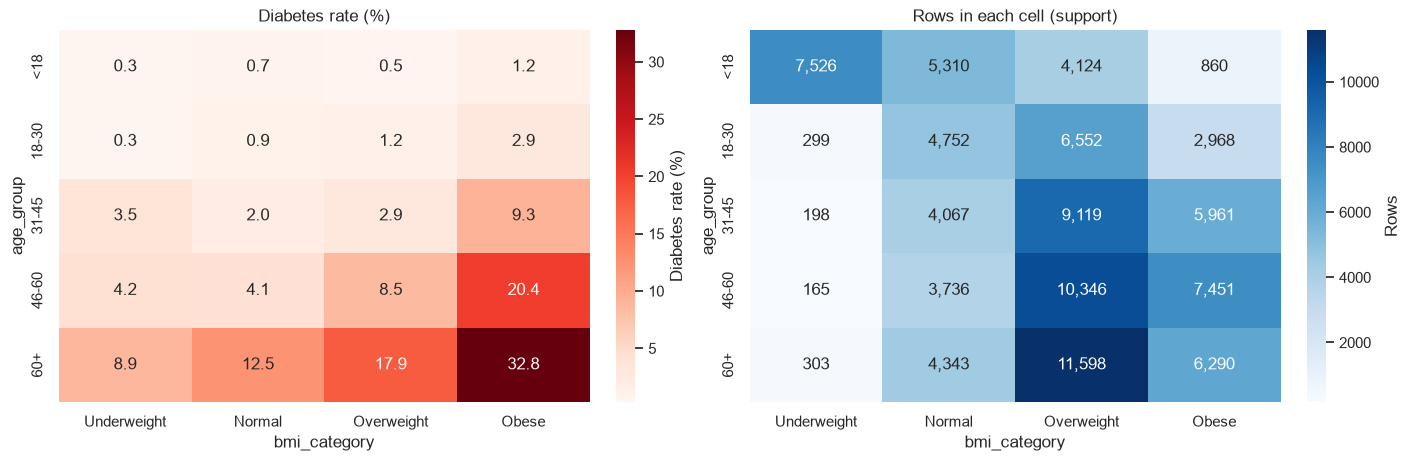

In [37]:
bmi_order = category_orders["bmi_category"]
rate_tbl = (pd.crosstab(eda["age_group"], eda["bmi_category"], values=eda[TARGET],
                        aggfunc="mean").reindex(index=age_order, columns=bmi_order) * 100)
support_tbl = pd.crosstab(eda["age_group"], eda["bmi_category"]).reindex(index=age_order, columns=bmi_order)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), constrained_layout=True)
sns.heatmap(rate_tbl, annot=True, fmt=".1f", cmap="Reds", ax=axes[0], cbar_kws={"label": "Diabetes rate (%)"})
axes[0].set_title("Diabetes rate (%)")
sns.heatmap(support_tbl, annot=True, fmt=",d", cmap="Blues", ax=axes[1], cbar_kws={"label": "Rows"})
axes[1].set_title("Rows in each cell (support)")
plt.show()

# Part 7: Final Review




**Question:** Is the final dataset clean, and what did we learn?

In [38]:
print("Final shape:", df.shape)
print("Missing values:", df.isna().sum().sum())
print("Duplicates:", df.duplicated().sum())
print("New features:", ["bmi_capped", "age_group", "risk_score", "bmi_category", "hba1c_x_glucose", "age_x_bmi"])
display(df.head())
df.to_csv("diabetes_cleaned.csv", index=False)

Final shape: (95968, 15)
Missing values: 0
Duplicates: 0
New features: ['bmi_capped', 'age_group', 'risk_score', 'bmi_category', 'hba1c_x_glucose', 'age_x_bmi']


,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes,bmi_capped,age_group,risk_score,bmi_category,hba1c_x_glucose,age_x_bmi
0,Female,80.0,0,1,never,25.19,6.6,140,0,25.19,60+,3,Overweight,924.0,2015.20
1,Female,54.0,0,0,unknown,27.32,6.6,80,0,27.32,46-60,2,Overweight,528.0,1475.28
2,Male,28.0,0,0,never,27.32,5.7,158,0,27.32,18-30,0,Overweight,900.6,764.96
3,Female,36.0,0,0,current,23.45,5.0,155,0,23.45,31-45,0,Normal,775.0,844.20
4,Male,76.0,1,1,current,20.14,4.8,155,0,20.14,60+,3,Normal,744.0,1530.64
